In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from torcheeg import transforms
from datasets.HBUEDDataset import HBUEDDataset
from torch.utils.data import Dataset, random_split, DataLoader
from torch.nn.utils.rnn import pad_sequence
from collections import OrderedDict
import random
import numpy as np
import torch.nn as nn
import torch
from einops.layers.torch import Rearrange
from tqdm import tqdm
from einops import rearrange, repeat
import matplotlib.pyplot as plt
import pandas as pd

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    
output_dir = project_root / 'HBUED' / 'tmp_out'
output_dir.mkdir(parents=True, exist_ok=True)


In [2]:
params = {
    'window': 20, 
    'c_size': 200, 
    'batch_size': 1024,
    'epochs': 20, 
    'lr': 1e-4,
    'num_electrodes':32,
    'chunk_size': 200,
    't_patch_size': 40, 
    'hid_channels': 128, 
    'depth': 3, 
    'heads': 4,
    'head_channels': 32,
    'mlp_channels': 32,
    'num_classes': 2,
    'embed_dropout': 0.0,
    'dropout': 0.2, 
    'pool_func': 'cls'}

### Trial caching and indexing.

To avoid using too much storage for the preprocessed signals, the index stores integers rather than copies of the signals. LMDB window-key ordering is used to ensure compatibility with TorchEEG.

In [3]:
class KeyedHBUEDDataset(HBUEDDataset):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        info = self.info_io.read_all()
        if not self.keys:
            raise ValueError('No trials found; check root_path.')
        if ('key' not in info or info['key'].duplicated().any()
                or set(info['key']) != set(self.keys)):
            raise ValueError('Cache metadata mismatch; use a fresh io_path.')
        self.info_by_key = info.set_index('key', drop=False)

    def __getitem__(self, index):
        key = self.keys[index]
        eeg = self.eeg_io.read_eeg(key)
        info = self.info_by_key.loc[key].to_dict()
        if self.online_transform is not None:
            eeg = self.online_transform(eeg=eeg)['eeg']
        y = info
        if self.label_transform is not None:
            y = self.label_transform(y=info)['y']
        return eeg, y


class WindowIndexDataset(Dataset):
    def __init__(self, trials, chunk_size=200, stride=20, max_cached_trials=128):
        if chunk_size <= 0 or stride <= 0 or max_cached_trials < 0:
            raise ValueError('Require positive chunk size/stride and nonnegative cache size.')
        self.trials = trials
        self.chunk_size = chunk_size
        self.stride = stride
        self.max_cached_trials = max_cached_trials
        self.cache = OrderedDict()
        entries = []
        for trial_index, key in enumerate(trials.keys):
            eeg, _ = trials[trial_index]
            if eeg.ndim != 2:
                raise ValueError(f'Expected channels × time for {key}.')
            for start in range(0, eeg.shape[1] - chunk_size + 1, stride):
                entries.append((f'{key}_start{start}', trial_index, start))
        # LMDB orders keys lexicographically, including the numeric suffixes.
        entries.sort(key=lambda entry: entry[0])
        self.locations = torch.tensor([(i, s) for _, i, s in entries], dtype=torch.int64)
        if not len(entries):
            raise ValueError('No complete windows available.')

    def __len__(self):
        return len(self.locations)

    def get_trial(self, trial_index):
        if trial_index in self.cache:
            self.cache.move_to_end(trial_index)
            return self.cache[trial_index]
        trial = self.trials[trial_index]
        if self.max_cached_trials:
            self.cache[trial_index] = trial
            if len(self.cache) > self.max_cached_trials:
                self.cache.popitem(last=False)
        return trial

    def __getitem__(self, index):
        trial_index, start = self.locations[index].tolist()
        eeg, label = self.get_trial(trial_index)
        return trial_index, eeg, start, label


def collate_windows(samples):
    # Send each distinct full trial only once per batch. No windows sliced here.
    unique, trials, lengths, rows, starts, labels = {}, [], [], [], [], []
    for trial_id, eeg, start, label in samples:
        if trial_id not in unique:
            unique[trial_id] = len(trials)
            trials.append(eeg.transpose(0, 1))
            lengths.append(eeg.shape[1])
        rows.append(unique[trial_id])
        starts.append(start)
        labels.append(label)
    batch = {
        'trials': pad_sequence(trials, batch_first=True).transpose(1, 2),
        'trial_indices': torch.tensor(rows, dtype=torch.long),
        'starts': torch.tensor(starts, dtype=torch.long),
        'lengths': torch.tensor(lengths, dtype=torch.long),
    }
    return batch, torch.tensor(labels, dtype=torch.long).T.contiguous()


dataset = KeyedHBUEDDataset(
    io_path=str(output_dir / 'PeViT'),
    root_path=str(project_root.parent / 'Dataset' / 'HBUED' / 'original'),
    offline_transform=transforms.Compose([transforms.MeanStdNormalize()]),
    online_transform=transforms.Compose([transforms.ToTensor()]),
    label_transform=transforms.Compose([
        transforms.Select(['arousal', 'valence']), transforms.Binary(5.0)
    ]),
)
windows = WindowIndexDataset(dataset, params['c_size'], params['window'])
print(f'{len(dataset):,} trials in {len(windows):,} chunks')


1,200 trials in 933,600 chunks


In [4]:
def train(train_loader, val_loader, epochs, model, loss_fn, optimizer, target, model_path):
    best_v_acc = 0.0
    train_acc, train_loss, val_acc, val_loss = [], [], [], []
    for t in range(epochs):
        with tqdm(total=len(train_loader), unit='batch') as pbar:
            pbar.set_description(f'Epoch {t+1}/{epochs}')

            model.train()
            loss, tr_loss, tr_acc = 0, 0, 0
            for batch_idx, (X, y) in enumerate(train_loader):
                pbar.update(1)
                
                X = {key: value.to(device) for key, value in X.items()}
                y = y[target].to(device)

                pred = model(**X)
                loss = loss_fn(pred, y)
                tr_loss += loss.item()

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                tr_acc += (pred.argmax(1) == y).type(torch.float).sum().item()

            tr_loss /= len(train_loader)
            tr_acc /= len(train_loader.dataset)
            train_acc.append(tr_acc)
            train_loss.append(tr_loss)

            model.eval()
            v_loss, v_acc = 0, 0
            with torch.no_grad():
                for (X, y) in val_loader:
                    
                    X = {key: value.to(device) for key, value in X.items()}
                    y = y[target].to(device)

                    pred = model(**X)
                    v_loss += loss_fn(pred, y).item()

                    v_acc += (pred.argmax(1) == y).type(torch.float).sum().item()

            v_loss /= len(val_loader)
            v_acc /= len(val_loader.dataset)
            val_acc.append(v_acc)
            val_loss.append(v_loss)

            if v_acc > best_v_acc:
                best_v_acc = v_acc
                torch.save(model.state_dict(), model_path)
            
            pbar.set_postfix_str(f'loss:{tr_loss:>8f}, vloss:{v_loss:>8f}, acc:{100*tr_acc:>0.2f}%, vacc:{100*v_acc:>0.2f}%')

    return train_acc, val_acc, train_loss, val_loss

def test(loader, model, loss_fn, target):
    model.eval()
    loss, correct = 0, 0
    with torch.no_grad():
        for (X, y) in loader:
            
            X = {key: value.to(device) for key, value in X.items()}
            y = y[target].to(device)

            pred = model(**X)
            loss += loss_fn(pred, y.type(torch.int64)).item()

            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    loss /= len(loader)
    correct /= len(loader.dataset)

    return correct, loss

def testing(model_path, test_loader, model, loss_fn, target):
    # load the best model to test on test set
    print('Loading model from', model_path)
    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    test_acc, test_loss = test(test_loader, model, loss_fn, target)
    print(f"Test Set: Accuracy: {(100*test_acc):>0.2f}%, Avg loss: {test_loss:>8f}")

    return None

def train_plot(train_acc, val_acc, train_loss, val_loss):
    plt.subplot(2, 1, 1)
    plt.plot(train_acc, label='Training Accuracy')
    plt.plot(val_acc, label='Validation Accuracy')
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.legend(loc='lower right', fontsize=10)
    plt.ylabel('Accuracy', fontsize=12, weight='bold')
    plt.title('Training & Validation Accuracy', fontsize=14, weight='bold')

    plt.subplot(2, 1, 2)
    plt.plot(train_loss, label='Training Loss')
    plt.plot(val_loss, label='Validation Loss')
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.legend(loc='upper right', fontsize=10)
    plt.ylabel('Loss', fontsize=12, weight='bold')
    plt.title('Training & Validation Loss', fontsize=14, weight='bold')
    plt.xlabel('Epoch', fontsize=12, weight='bold')
    
    plt.tight_layout()
    plt.savefig(output_dir / 'plot.png')
    plt.show()

def save_metrics_to_csv(train_acc, val_acc, train_loss, val_loss, csv_path):
    """Save training metrics to CSV file."""
    epochs = list(range(1, len(train_acc) + 1))
    
    df = pd.DataFrame({
        'epoch': epochs,
        'loss': train_loss,
        'vloss': val_loss,
        'acc': train_acc,
        'vacc': val_acc
    })
    
    df.to_csv(csv_path, index=False)
    print(f"Metrics saved to {csv_path}")

In [5]:
split_generator = torch.Generator().manual_seed(seed)
n = len(windows)
n_test = int(0.2 * n)
n_train = n - n_test
train_dataset, test_dataset = random_split(windows, [n_train, n_test], generator=split_generator)

n_val = int(0.2 * n)
n_train2 = n_train - n_val
train_dataset, val_dataset = random_split(train_dataset, [n_train2, n_val], generator=split_generator)

train_loader = DataLoader(train_dataset, batch_size=params['batch_size'], shuffle=True, collate_fn=collate_windows,
                          generator=torch.Generator().manual_seed(seed + 1), num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=params['batch_size'], shuffle=False, collate_fn=collate_windows, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=params['batch_size'], shuffle=False, collate_fn=collate_windows, num_workers=0)

In [6]:
# Some are modified from TorchEEG

class PreNorm(nn.Module):
    def __init__(self, in_channels: int, fn: nn.Module):
        super(PreNorm, self).__init__()
        self.norm = nn.LayerNorm(in_channels)
        self.fn = fn

    def forward(self, x, **kwargs):
        return self.fn(self.norm(x), **kwargs)

class FeedForward(nn.Module):
    def __init__(self,
                 in_channels: int,
                 hid_channels: int,
                 dropout: float = 0.):
        super(FeedForward, self).__init__()
        self.net = nn.Sequential(nn.Linear(in_channels, hid_channels),
                                 nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(hid_channels, in_channels),
                                 nn.Dropout(dropout))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)
        
class Attention(nn.Module):
    def __init__(self,
                 hid_channels: int,
                 heads: int = 8,
                 head_channels: int = 64,
                 dropout: float = 0.):
        super(Attention, self).__init__()
        inner_channels = head_channels * heads
        project_out = not (heads == 1 and head_channels == hid_channels)

        self.heads = heads
        self.scale = head_channels**-0.5

        self.attend = nn.Softmax(dim=-1)
        self.dropout = nn.Dropout(dropout)

        self.to_qkv = nn.Linear(hid_channels, inner_channels * 3, bias=False)

        self.to_out = nn.Sequential(
            nn.Linear(inner_channels, hid_channels),
            nn.Dropout(dropout)) if project_out else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        qkv = self.to_qkv(x).chunk(3, dim=-1)
        q, k, v = map(
            lambda t: rearrange(t, 'b n (h d) -> b h n d', h=self.heads), qkv)

        dots = torch.matmul(q, k.transpose(-1, -2)) * self.scale

        attn = self.attend(dots)
        attn = self.dropout(attn)

        out = torch.matmul(attn, v)
        out = rearrange(out, 'b h n d -> b n (h d)')
        return self.to_out(out)

class Transformer(nn.Module):
    def __init__(self,
                 hid_channels: int,
                 depth: int,
                 heads: int,
                 head_channels: int,
                 mlp_channels: int,
                 dropout: float = 0.):
        super(Transformer, self).__init__()
        self.layers = nn.ModuleList([])
        for _ in range(depth):
            self.layers.append(
                nn.ModuleList([
                    PreNorm(
                        hid_channels,
                        Attention(hid_channels,
                                  heads=heads,
                                  head_channels=head_channels,
                                  dropout=dropout)
                    ),
                    PreNorm(
                        hid_channels,
                        FeedForward(hid_channels, mlp_channels,
                                    dropout=dropout))
                ]))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for attn, ff in self.layers:
            x = attn(x) + x
            x = ff(x) + x
        return x

class PeViT(nn.Module):
    '''
    Args:
       num_electrodes (int): The number of electrodes. (default: :obj:`32`)
        chunk_size (int): Number of data points included in each EEG chunk. (default: :obj:`128`)
        t_patch_size (int): The size of each input patch at the temporal (chunk size) dimension. (default: :obj:`32`)
        patch_size (tuple): The size (resolution) of each input patch. (default: :obj:`(3, 3)`)
        hid_channels (int): The feature dimension of embeded patch. (default: :obj:`32`)
        depth (int): The number of attention layers for each transformer block. (default: :obj:`3`)
        heads (int): The number of attention heads for each attention layer. (default: :obj:`4`)
        head_channels (int): The dimension of each attention head for each attention layer. (default: :obj:`8`)
        mlp_channels (int): The number of hidden nodes in the fully connected layer of each transformer block. (default: :obj:`64`)
        num_classes (int): The number of classes to predict. (default: :obj:`2`)
        embed_dropout (float): Probability of an element to be zeroed in the dropout layers of the embedding layers. (default: :obj:`0.0`)
        dropout (float): Probability of an element to be zeroed in the dropout layers of the transformer layers. (default: :obj:`0.0`)
        pool_func (str): The pool function before the classifier, optionally including :obj:`cls` and :obj:`mean`, where :obj:`cls` represents selecting classification-related token and :obj:`mean` represents the average pooling. (default: :obj:`cls`)
    '''
    
    def __init__(self,
                 num_electrodes: int = 32,
                 chunk_size: int = 200,
                 t_patch_size: int = 40,
                 hid_channels: int = 32,
                 depth: int = 3,
                 heads: int = 4,
                 head_channels: int = 64,
                 mlp_channels: int = 64,
                 num_classes: int = 2,
                 embed_dropout: float = 0.,
                 dropout: float = 0.,
                 pool_func: str = 'cls'):
        super(PeViT, self).__init__()
        self.num_electrodes = num_electrodes
        self.chunk_size = chunk_size
        self.t_patch_size = t_patch_size
        self.hid_channels = hid_channels
        self.depth = depth
        self.heads = heads
        self.head_channels = head_channels
        self.mlp_channels = mlp_channels
        self.num_classes = num_classes
        self.embed_dropout = embed_dropout
        self.dropout = dropout
        self.pool_func = pool_func

        assert chunk_size % t_patch_size == 0, f'EEG chunk size {chunk_size} must be divisible by the temporal patch size {t_patch_size}.'

        num_patches = chunk_size // t_patch_size
        patch_channels = num_electrodes * t_patch_size

        assert pool_func in {
            'cls', 'mean'
        }, 'pool_func must be either cls (cls token) or mean (mean pooling)'

        self.to_patch_embedding = nn.Sequential(
            Rearrange('b c (w p) -> b w (c p)', p=t_patch_size),
            nn.Linear(patch_channels, hid_channels),
        )
        
        self.pos_embedding = nn.Parameter(
            torch.randn(1, num_patches + 1, hid_channels))
        self.cls_token = nn.Parameter(torch.randn(1, 1, hid_channels))
        self.dropout = nn.Dropout(embed_dropout)

        self.transformer = Transformer(hid_channels, depth, heads,
                                       head_channels, mlp_channels, dropout)

        self.pool_func = pool_func

        self.mlp_head = nn.Sequential(nn.LayerNorm(hid_channels),
                                      nn.Linear(hid_channels, num_classes))

    def extract_windows(self, trials, trial_indices, starts, lengths):
        if trial_indices.ndim != 1 or starts.shape != trial_indices.shape:
            raise ValueError('Expected one trial index and start per window.')
        if ((starts < 0) | (starts + self.chunk_size > lengths[trial_indices])).any():
            raise ValueError('Window extends beyond its unpadded trial.')
        times = starts[:, None] + torch.arange(self.chunk_size, device=trials.device)
        # Advanced indexing gathers only the requested windows, not all overlaps.
        return trials[trial_indices[:, None], :, times].transpose(1, 2).contiguous()

    def forward(self, trials, trial_indices, starts, lengths):
        x = self.extract_windows(trials, trial_indices, starts, lengths)
        return self.classify_windows(x)

    def classify_windows(self, x):
        x = self.to_patch_embedding(x)
        x = rearrange(x, 'b ... d -> b (...) d')
        b, n, _ = x.shape

        cls_tokens = repeat(self.cls_token, '1 1 d -> b 1 d', b=b)
        x = torch.cat((cls_tokens, x), dim=1)
        x += self.pos_embedding[:, :(n + 1)]
        x = self.dropout(x)

        x = self.transformer(x)

        x = x.mean(dim=1) if self.pool_func == 'mean' else x[:, 0]

        return self.mlp_head(x)

In [7]:
loss_fn = nn.CrossEntropyLoss()
epochs = params['epochs']
lr = params['lr']

init_model = PeViT(
    num_electrodes = params['num_electrodes'],
    chunk_size = params['chunk_size'],
    t_patch_size = params['t_patch_size'],
    hid_channels = params['hid_channels'],
    depth = params['depth'],
    heads = params['heads'],
    head_channels = params['head_channels'], 
    mlp_channels = params['mlp_channels'],
    num_classes = params['num_classes'],
    embed_dropout = params['embed_dropout'],
    dropout = params['dropout'],
    pool_func = params['pool_func']
    ).to(device)

In [8]:
model = init_model
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
model_path = output_dir / 'arousal_w20_c200.pt'
target = 0 # 0: "arousal", 1: "valence"

train_acc, val_acc, train_loss, val_loss = train(train_loader, val_loader, 
                                    epochs, model, loss_fn, optimizer, target, model_path)

Epoch 20/20: 100%|██████████| 548/548 [08:27<00:00,  1.08batch/s, loss:0.455914, vloss:0.445491, acc:77.07%, vacc:77.62%]


Metrics saved to /home/wawan/DL/EEG/PeViT/HBUED/tmp_out/arousal_w20_c200_metrics.csv
Loading model from /home/wawan/DL/EEG/PeViT/HBUED/tmp_out/arousal_w20_c200.pt
Test Set: Accuracy: 77.43%, Avg loss: 0.446883


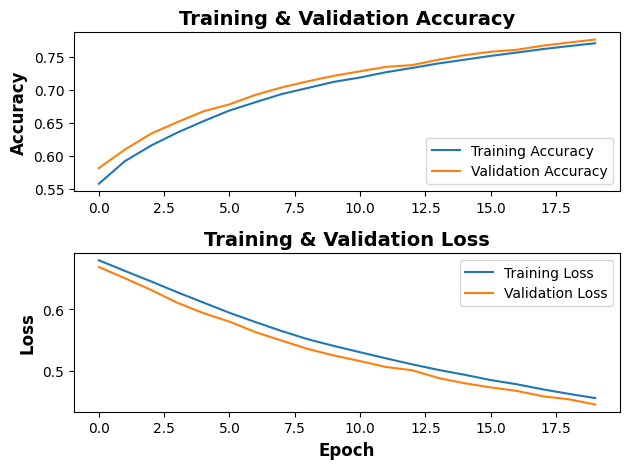

In [9]:
csv_path = output_dir / 'arousal_w20_c200_metrics.csv'
save_metrics_to_csv(train_acc, val_acc, train_loss, val_loss, csv_path)

testing(model_path, test_loader, model, loss_fn, target)
train_plot(train_acc, val_acc, train_loss, val_loss)